# Task 64: Out-of-Distribution Stress Tests

Create synthetic marginal-tail edge cases from training statistics and inspect confidence, continuous-feature tail proximity, and distance from observed training data. Synthetic cases have no labels.

Synthetic OOD stress cases have no labels; report confidence/distance, not accuracy.


,Predicted probability,Confidence,Continuous features near 1–99% tails,Nearest train standardized distance
Scenario,,,,
age lower-tail,0.610,0.610,0.2,2.150
age upper-tail,0.525,0.525,0.2,2.183
trestbps lower-tail,0.717,0.717,0.2,2.251
trestbps upper-tail,0.289,0.711,0.2,2.808
chol lower-tail,0.585,0.585,0.2,1.869
chol upper-tail,0.506,0.506,0.2,2.782
thalach lower-tail,0.342,0.658,0.2,1.667
thalach upper-tail,0.700,0.700,0.2,2.088
oldpeak lower-tail,0.653,0.653,0.2,1.797


Median held-out confidence: 0.872
Median synthetic-case confidence: 0.658


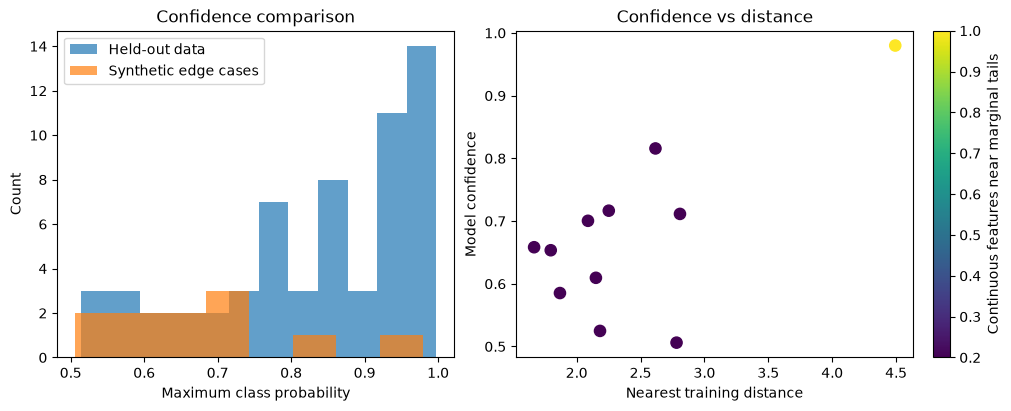

Synthetic combinations may not be clinically valid. Distance is a diagnostic, not a calibrated OOD detector; high confidence far from training support should trigger review rather than trust.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path('heart.csv'), Path('Task_64_Out_of_Distribution_Stress_Testing/heart.csv'), Path('Heart_Disease_Tasks/Task_64_Out_of_Distribution_Stress_Testing/heart.csv')]
data = pd.read_csv(next(path for path in paths if path.is_file())).drop_duplicates().reset_index(drop=True)
features = [name for name in ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal'] if name in data]
X, y = data[features].to_numpy(float), data['target'].to_numpy(int)


def stratified_split(labels, fraction, seed):
    rng = np.random.default_rng(seed)
    first, second = [], []
    for label in np.unique(labels):
        indices = np.flatnonzero(labels == label)
        rng.shuffle(indices)
        cut = round(fraction * len(indices))
        first.extend(indices[:cut])
        second.extend(indices[cut:])
    rng.shuffle(first)
    rng.shuffle(second)
    return np.array(first), np.array(second)


train_indices, test_indices = stratified_split(y, 0.8, 64)
X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
means, scales = X_train.mean(axis=0), X_train.std(axis=0)
scales[scales == 0] = 1.0
X_train_scaled, X_test_scaled = (X_train - means) / scales, (X_test - means) / scales


class ManualLogistic:
    def fit(self, x, labels):
        self.weights = np.zeros(x.shape[1])
        self.bias = 0.0
        for _ in range(1400):
            probability = 1 / (1 + np.exp(-np.clip(x @ self.weights + self.bias, -35, 35)))
            error = probability - labels
            self.weights -= 0.06 * (x.T @ error / len(labels) + 0.02 * self.weights)
            self.bias -= 0.06 * error.mean()
        return self

    def predict_probability(self, x):
        return 1 / (1 + np.exp(-np.clip(x @ self.weights + self.bias, -35, 35)))


model = ManualLogistic().fit(X_train_scaled, y_train)
continuous_features = [name for name in ['age', 'trestbps', 'chol', 'thalach', 'oldpeak'] if name in features]
categorical_features = [name for name in features if name not in continuous_features]
low_quantile = np.quantile(X_train, 0.01, axis=0)
high_quantile = np.quantile(X_train, 0.99, axis=0)
median = np.median(X_train, axis=0)
mode = {name: float(pd.Series(X_train[:, features.index(name)]).mode().iloc[0]) for name in categorical_features}
scenarios = []
for feature in continuous_features:
    column = features.index(feature)
    for tail, value in [('lower-tail', low_quantile[column]), ('upper-tail', high_quantile[column])]:
        row = median.copy()
        for category, category_mode in mode.items():
            row[features.index(category)] = category_mode
        row[column] = value
        scenarios.append((f'{feature} {tail}', row))
combined = median.copy()
for category, category_mode in mode.items():
    combined[features.index(category)] = category_mode
for feature in ['age', 'trestbps', 'chol', 'oldpeak']:
    if feature in features:
        combined[features.index(feature)] = high_quantile[features.index(feature)]
if 'thalach' in features:
    combined[features.index('thalach')] = low_quantile[features.index('thalach')]
scenarios.append(('Combined marginal tails', combined))

synthetic = np.vstack([row for _, row in scenarios])
synthetic_scaled = (synthetic - means) / scales
probabilities = model.predict_probability(synthetic_scaled)
confidence = np.maximum(probabilities, 1 - probabilities)
near_tail = np.zeros((len(synthetic), len(continuous_features)), dtype=bool)
for column_index, feature in enumerate(continuous_features):
    column = features.index(feature)
    low, high = low_quantile[column], high_quantile[column]
    tail_width = max((high - low) * 0.01, 1e-8)
    near_tail[:, column_index] = (synthetic[:, column] <= low + tail_width) | (synthetic[:, column] >= high - tail_width)
tail_fraction = near_tail.mean(axis=1)
nearest_distance = [float(np.sqrt(np.min(np.sum((X_train_scaled - row) ** 2, axis=1)))) for row in synthetic_scaled]
summary = pd.DataFrame({'Scenario': [name for name, _ in scenarios], 'Predicted probability': probabilities, 'Confidence': confidence, 'Continuous features near 1–99% tails': tail_fraction, 'Nearest train standardized distance': nearest_distance}).set_index('Scenario')
print('Synthetic OOD stress cases have no labels; report confidence/distance, not accuracy.')
display(summary.round(3))

test_probability = model.predict_probability(X_test_scaled)
test_confidence = np.maximum(test_probability, 1 - test_probability)
print('Median held-out confidence:', round(float(np.median(test_confidence)), 3))
print('Median synthetic-case confidence:', round(float(np.median(confidence)), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].hist(test_confidence, bins=12, alpha=0.7, label='Held-out data')
axes[0].hist(confidence, bins=8, alpha=0.7, label='Synthetic edge cases')
axes[0].set_xlabel('Maximum class probability')
axes[0].set_ylabel('Count')
axes[0].set_title('Confidence comparison')
axes[0].legend()
scatter = axes[1].scatter(nearest_distance, confidence, c=tail_fraction, cmap='viridis', s=65)
axes[1].set_xlabel('Nearest training distance')
axes[1].set_ylabel('Model confidence')
axes[1].set_title('Confidence vs distance')
fig.colorbar(scatter, ax=axes[1], label='Continuous features near marginal tails')
plt.show()
print('Synthetic combinations may not be clinically valid. Distance is a diagnostic, not a calibrated OOD detector; high confidence far from training support should trigger review rather than trust.')